# 02 · Preprocesamiento y construcción de imágenes

**Fase CRISP-DM:** 3 – Preparación de los datos

A partir de las conclusiones del EDA, cada muestra (un `eeg_id`) se transforma en una imagen de
**8 tiles** (128 × 256 cada una, frecuencia × tiempo) que las CNNs preentrenadas pueden consumir:

| Tiles 1–4 (columna izquierda) | Tiles 5–8 (columna derecha) |
|---|---|
| Espectrogramas de Kaggle, 10 min, regiones LL / LP / RP / RL | Espectrogramas calculados del EEG crudo, 50 s, cadenas LL / LP / RP / RR |

El código está en `src/features.py` y el precálculo de todo el dataset en `src/build_cache.py`
(`python -m src.build_cache`), que genera `images.npy` (N × 8 × 128 × 256, float16),
`meta.csv` (objetivo, votos, fold) y `band_features.csv` (features clásicas para el baseline).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from src.config import CACHE_DIR, FIGURES_DIR, TARGETS, CLASSES, EEG_FS, CHAINS
from src.features import (read_eeg, eeg_window, clean_eeg, bipolar_montage, eeg_spec_tiles,
                          read_kaggle_spectrogram, kaggle_spec_window, kaggle_spec_tiles, _SOS)
from src.viz import set_style, CLASS_COLORS
set_style()
FIG = FIGURES_DIR / "preprocesamiento"; FIG.mkdir(exist_ok=True, parents=True)
meta = pd.read_csv(CACHE_DIR / "meta.csv")
print(meta.shape); meta.head()

(17089, 17)


,eeg_id,spectrogram_id,patient_id,eeg_offset,spec_offset,n_subwindows,total_votes,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote,target,expert_consensus,fold,cache_ok
0,1628180742,353733,42516,24.0,24.0,9,3.0,1.0,0.0000,0.000000,0.000,0.000000,0.000000,0,Seizure,4,True
1,2277392603,924234,30539,2.0,2.0,2,11.0,0.0,0.0000,0.454545,0.000,0.090909,0.454545,2,GPD,0,True
2,722738444,999431,56885,10.0,10.0,11,16.0,0.0,0.0625,0.000000,0.875,0.000000,0.062500,3,LRDA,1,True
3,387987538,1084844,4264,8.0,8.0,6,3.0,0.0,0.0000,0.000000,1.000,0.000000,0.000000,3,LRDA,4,True
4,2175806584,1219001,23435,18.0,18.0,2,3.0,1.0,0.0000,0.000000,0.000,0.000000,0.000000,0,Seizure,2,True


## 1. Consolidación por EEG y partición por paciente
- Una fila por `eeg_id`: sub-ventana central para recortar la señal; objetivo = media de las
  distribuciones de votos normalizadas de todas sus sub-ventanas.
- `total_votes` = votos medios por sub-ventana (para separar alta/baja calidad).
- 5 folds con `StratifiedGroupKFold(groups=patient_id)`.

In [2]:
print("Muestras:", len(meta), "| pacientes:", meta.patient_id.nunique(), "| errores de caché:", (~meta.cache_ok).sum())
print("Alta calidad (>=10 votos):", (meta.total_votes >= 10).sum())
pd.crosstab(meta.fold, meta.total_votes >= 10, margins=True).rename(columns={True: ">=10", False: "<10"})

Muestras: 17089 | pacientes: 1950 | errores de caché: 0
Alta calidad (>=10 votos): 5396


total_votes,<10,>=10,All
fold,,,
0,2333,1085,3418
1,2363,1055,3418
2,2375,1043,3418
3,2295,1123,3418
4,2327,1090,3417
All,11693,5396,17089


## 2. Limpieza del EEG crudo
1. Imputación de NaN con la media del canal (0 si el canal está vacío).
2. Filtro Butterworth pasa-banda **0.5–40 Hz** (orden 4, fase cero con `sosfiltfilt`): elimina la
   deriva DC y el ruido de línea de 50/60 Hz.
3. Recorte de amplitud a **±1024 µV** para acotar artefactos.
4. **Montaje bipolar "doble banana"**: diferencias entre electrodos vecinos, que es como los
   neurólogos leen el EEG y resalta la actividad focal.

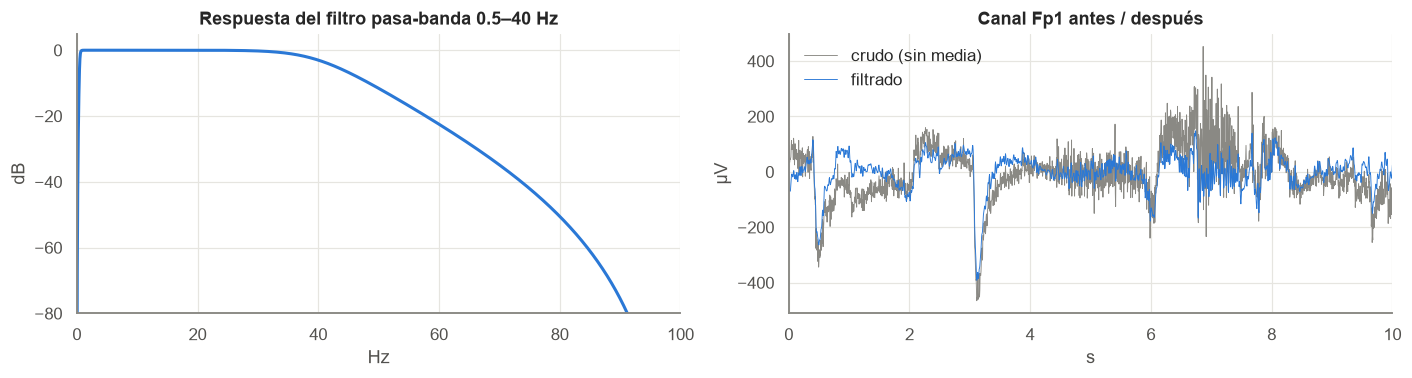

In [3]:
w, h = signal.sosfreqz(_SOS, worN=4096, fs=EEG_FS)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(w, 20 * np.log10(np.abs(h) + 1e-12), color="#2a78d6", lw=2)
axes[0].set_xlim(0, 100); axes[0].set_ylim(-80, 5); axes[0].set_xlabel("Hz"); axes[0].set_ylabel("dB")
axes[0].set_title("Respuesta del filtro pasa-banda 0.5–40 Hz")

r = meta[meta.total_votes >= 10].iloc[5]
raw = eeg_window(read_eeg(r.eeg_id), r.eeg_offset)
cl = clean_eeg(raw)
t = np.arange(len(raw)) / EEG_FS
axes[1].plot(t, raw["Fp1"] - raw["Fp1"].mean(), lw=0.6, color="#8a8984", label="crudo (sin media)")
axes[1].plot(t, cl["Fp1"], lw=0.6, color="#2a78d6", label="filtrado")
axes[1].set_xlim(0, 10); axes[1].set_xlabel("s"); axes[1].set_ylabel("µV"); axes[1].legend()
axes[1].set_title("Canal Fp1 antes / después")
fig.tight_layout(); fig.savefig(FIG / "filtro.png"); plt.show()

## 3. Del EEG a espectrogramas por cadena
Para cada una de las 4 derivaciones de una cadena se calcula una STFT (ventana Hann de 256 muestras =
1.28 s, salto de 40 muestras = 0.2 s, `nfft`=1024), se conserva 0.5–20 Hz, se **promedia la potencia
de las 4 derivaciones**, se toma el logaritmo y se estandariza la tile (media 0, desviación 1).
Para los espectrogramas de Kaggle: ventana de 10 min, log con recorte en [e⁻⁴, e⁸], misma
estandarización. Ambas fuentes se re-muestrean a 128 × 256.

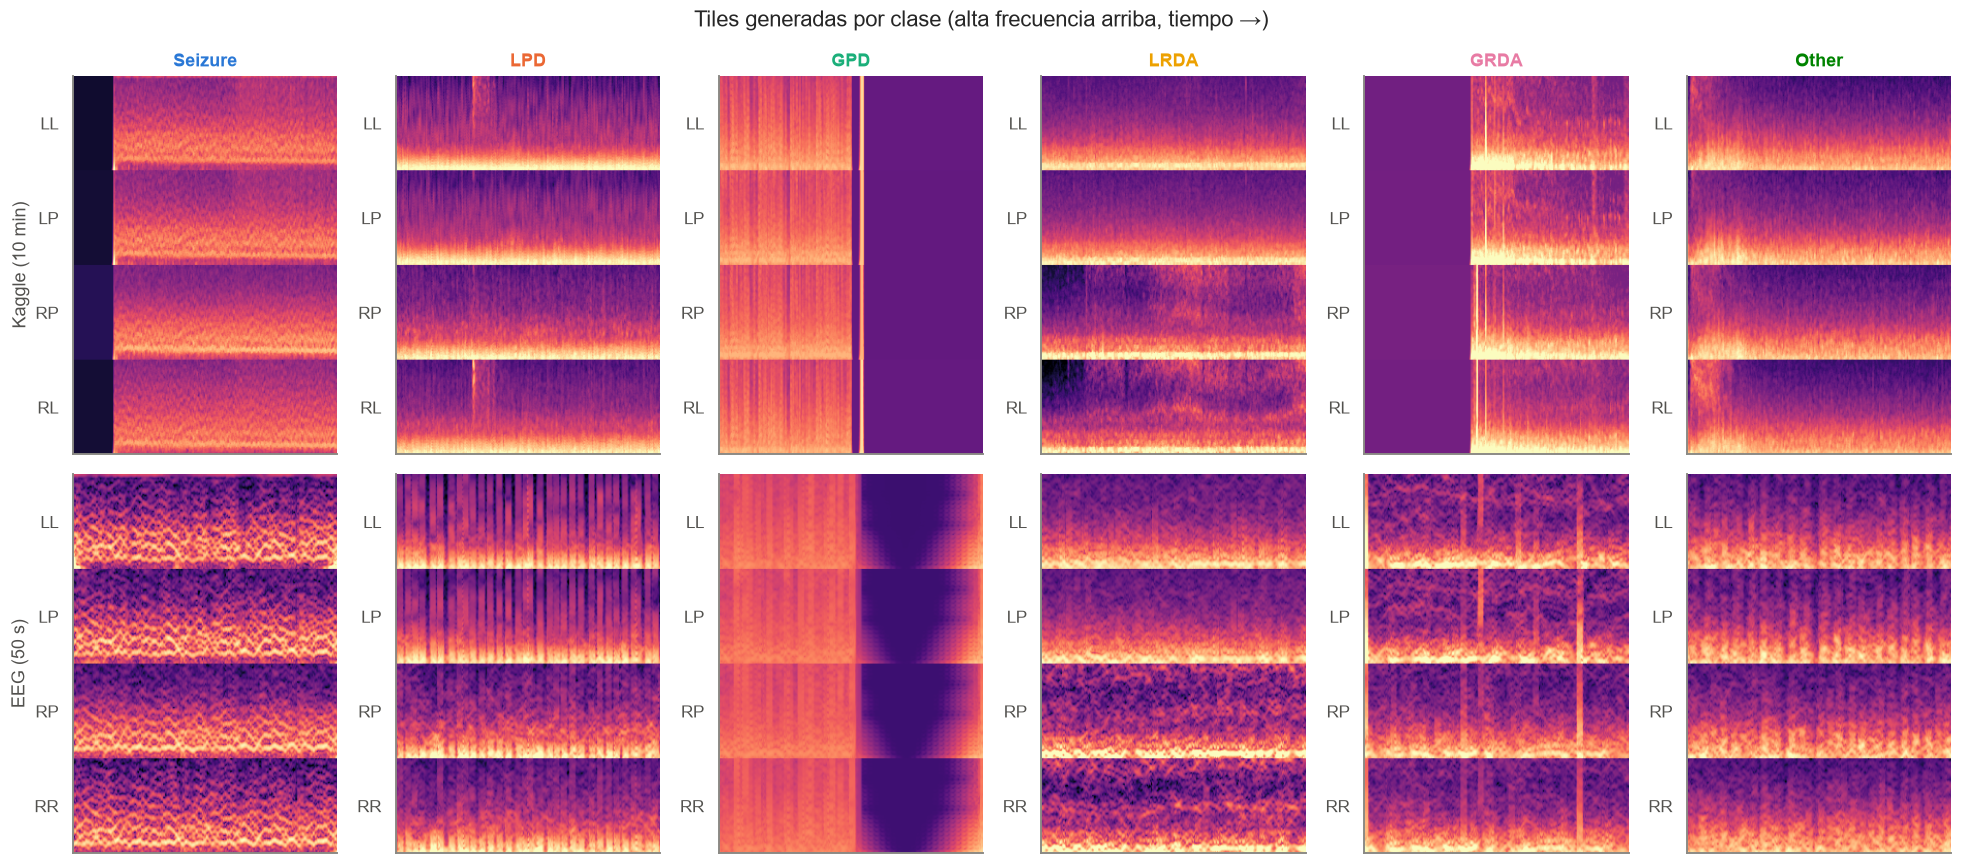

In [4]:
def show_sample(row, ax_k, ax_e):
    ks = kaggle_spec_tiles(kaggle_spec_window(read_kaggle_spectrogram(row.spectrogram_id), row.spec_offset))
    es = eeg_spec_tiles(eeg_window(read_eeg(row.eeg_id), row.eeg_offset))
    ax_k.imshow(np.concatenate(ks, 0), aspect="auto", cmap="magma", vmin=-2.5, vmax=2.5)
    ax_e.imshow(np.concatenate(es, 0), aspect="auto", cmap="magma", vmin=-2.5, vmax=2.5)
    for ax in (ax_k, ax_e):
        ax.set_xticks([]); ax.set_yticks([64 + 128 * i for i in range(4)]); ax.grid(False)
    ax_k.set_yticklabels(["LL", "LP", "RP", "RL"]); ax_e.set_yticklabels(["LL", "LP", "RP", "RR"])

fig, axes = plt.subplots(2, 6, figsize=(18, 8))
for i, c in enumerate(CLASSES):
    cand = meta[(meta.expert_consensus == c) & (meta.total_votes >= 10) & (meta[TARGETS].max(axis=1) >= .75)]
    row = cand.sample(1, random_state=1).iloc[0]
    show_sample(row, axes[0, i], axes[1, i])
    axes[0, i].set_title(c, color=CLASS_COLORS[c])
axes[0, 0].set_ylabel("Kaggle (10 min)"); axes[1, 0].set_ylabel("EEG (50 s)")
fig.suptitle("Tiles generadas por clase (alta frecuencia arriba, tiempo →)")
fig.tight_layout(); fig.savefig(FIG / "tiles_por_clase.png"); plt.show()

Se aprecian las firmas esperadas: actividad rápida y rítmica en *Seizure*, descargas repetidas
(líneas verticales) en las cadenas izquierdas en *LPD*, energía concentrada en las frecuencias más bajas
en *LRDA/GRDA*.

**Segmentos faltantes:** algunas muestras tienen tramos sin datos — bloques de color uniforme en los
espectrogramas de Kaggle (NaN imputados al piso de potencia) y tramos planos en el EEG (NaN imputados
con la media; la forma de "V" en el ejemplo GPD es el efecto de borde de la STFT/filtro). Se conservan:
la CNN ve ambas fuentes y puede apoyarse en la que tenga datos, y el enmascarado de entrenamiento
(abajo) simula precisamente este tipo de huecos.

## 4. Imagen final que recibe la CNN
Las 8 tiles se acomodan en una imagen de **512 × 512 × 1 canal** (las CNNs de `timm` adaptan la
primera convolución preentrenada a 1 canal sumando los pesos RGB). Durante el entrenamiento se aplican,
en GPU:
- **Intercambio de hemisferios** (p=0.5): LL↔RR y LP↔RP. Ninguna clase depende del lado, así que
  la etiqueta no cambia y se duplica efectivamente la variedad de casos lateralizados.
- **Enmascarado tiempo/frecuencia** estilo SpecAugment (2 franjas de cada tipo, hasta 1/8 del tamaño).

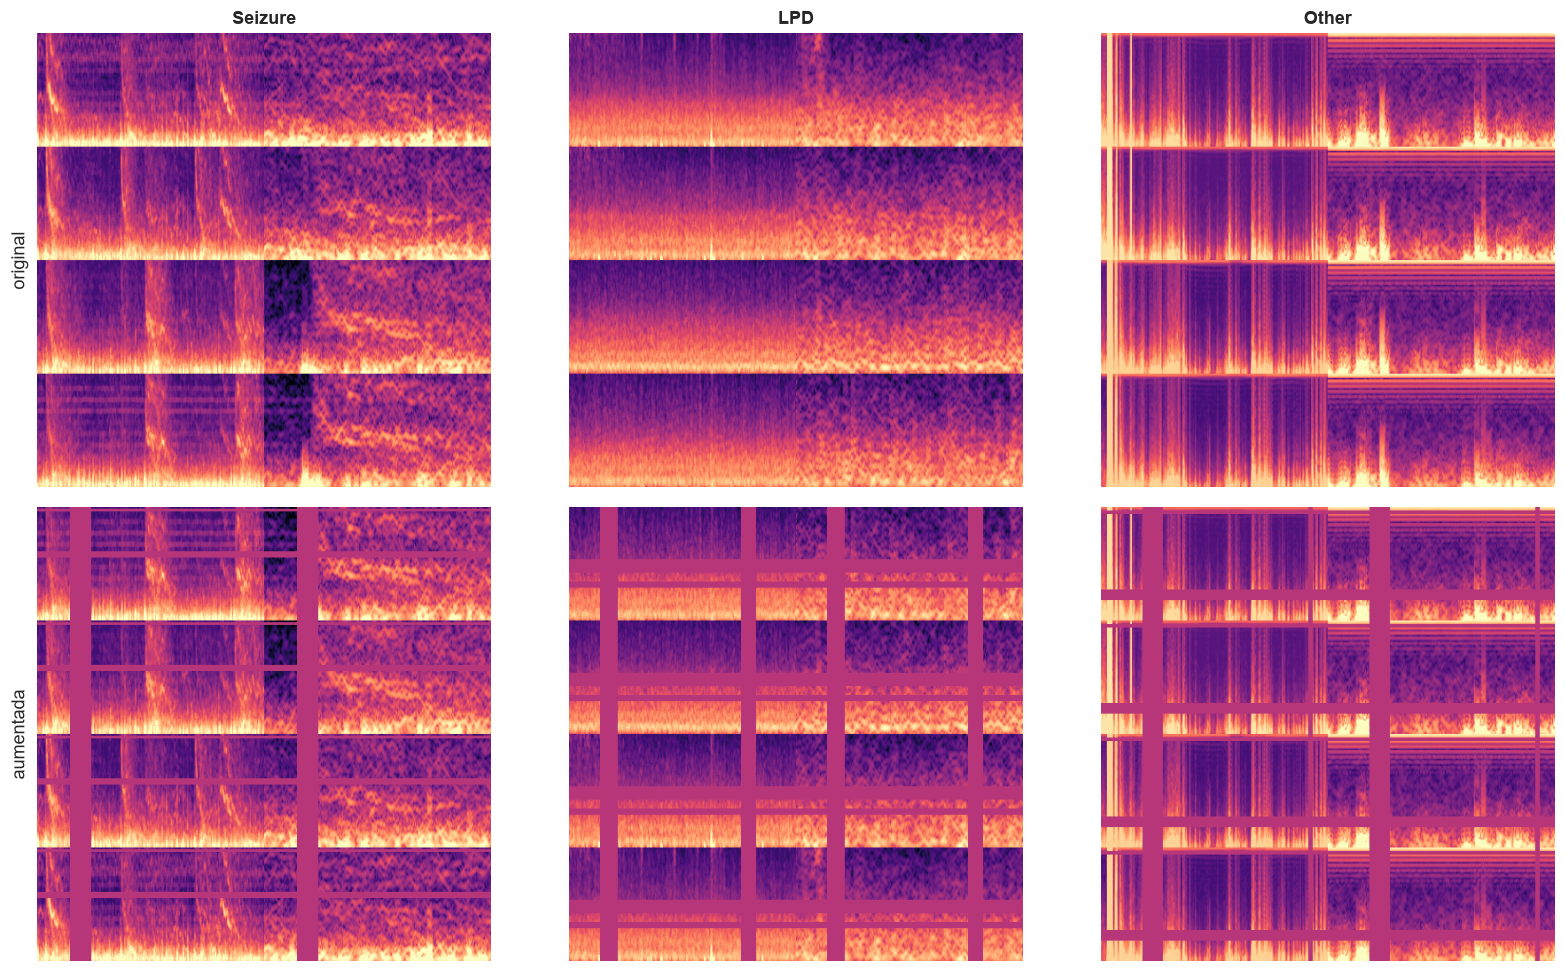

In [5]:
import torch
from src.train import assemble, augment
X = np.load(CACHE_DIR / "images.npy", mmap_mode="r")
idx = meta[(meta.total_votes >= 10)].sample(3, random_state=0).index.to_numpy()
xb = torch.from_numpy(np.asarray(X[np.sort(idx)])).float()
torch.manual_seed(0)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j in range(3):
    axes[0, j].imshow(assemble(xb, "both")[j, 0], cmap="magma", vmin=-2.5, vmax=2.5)
    axes[1, j].imshow(assemble(augment(xb), "both")[j, 0], cmap="magma", vmin=-2.5, vmax=2.5)
    axes[0, j].set_title(meta.loc[np.sort(idx)[j], "expert_consensus"])
    for ax in axes[:, j]: ax.axis("off")
axes[0, 0].text(-30, 256, "original", rotation=90, va="center", fontsize=12)
axes[1, 0].text(-30, 256, "aumentada", rotation=90, va="center", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "imagen_entrada.png"); plt.show()

## 5. Verificación del caché

In [6]:
sub = np.asarray(X[np.random.default_rng(0).choice(len(X), 500, replace=False)], dtype=np.float32)
print("Forma total:", X.shape, f"| {X.nbytes / 1e9:.1f} GB")
print("NaN:", np.isnan(sub).sum(), "| media por tile:", sub.mean((0, 2, 3)).round(3), "| std:", sub.std((0, 2, 3)).round(3))
feats = pd.read_csv(CACHE_DIR / "band_features.csv")
print("Features clásicas:", feats.shape, "| NaN:", int(feats.isna().sum().sum()))
feats.describe().T.head(12).round(3)

Forma total: (17089, 8, 128, 256) | 9.0 GB


NaN: 0 | media por tile: [-0. -0.  0.  0.  0.  0. -0.  0.] | std: [0.999 0.999 1.    1.    1.    1.    1.    1.   ]
Features clásicas: (17089, 65) | NaN: 0


,count,mean,std,min,25%,50%,75%,max
k_LL_delta_mean,17089.0,0.745,0.162,0.008,0.683,0.785,0.854,0.990
k_LL_delta_std,17089.0,0.110,0.081,0.003,0.056,0.088,0.136,0.495
k_LL_theta_mean,17089.0,0.122,0.069,0.000,0.074,0.108,0.152,0.687
k_LL_theta_std,17089.0,0.051,0.028,0.001,0.032,0.046,0.065,0.266
k_LL_alpha_mean,17089.0,0.057,0.051,0.000,0.026,0.044,0.070,0.650
k_LL_alpha_std,17089.0,0.031,0.026,0.000,0.013,0.024,0.041,0.304
k_LL_beta_mean,17089.0,0.056,0.095,0.000,0.014,0.028,0.057,0.958
k_LL_beta_std,17089.0,0.035,0.042,0.000,0.009,0.021,0.045,0.438
k_LL_logpow,17089.0,7.169,2.749,0.434,5.596,6.508,7.663,18.666
k_LP_delta_mean,17089.0,0.734,0.163,0.002,0.665,0.771,0.847,0.989
